# Task 4 · Modeling & Evaluation
**PowerCo SME churn (BCG X Data Science Job Simulation, Forage)**

Questions this notebook answers:
1. How well can a Random Forest predict which SME clients will churn?
2. With only ~10% churners, how do we turn the model into something the retention team can use?
3. Do price features carry real predictive power, or do other drivers dominate?
4. If PowerCo only contacts the riskiest 10% of clients, how much churn and margin does that cover?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics

sns.set_theme(style="whitegrid")
SEED = 42

df = pd.read_csv("../data/data_for_predictions.csv")
y = df["churn"]
X = df.drop(columns=["id", "churn"])
print(X.shape, f"churn rate = {y.mean():.1%}")

(14606, 39) churn rate = 9.7%


## 1. Train / test split
A stratified 75 / 25 split keeps the ~10% churn rate identical in both sets; the test set is only used for final evaluation.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
print("train:", X_train.shape, f"churn {y_train.mean():.1%}")
print("test: ", X_test.shape, f"churn {y_test.mean():.1%}")

train: (10954, 39) churn 9.7%
test:  (3652, 39) churn 9.7%


## 2. Baseline Random Forest (default 0.5 threshold)

In [3]:
rf = RandomForestClassifier(n_estimators=500, min_samples_leaf=2, random_state=SEED, n_jobs=-1)
rf.fit(X_train, y_train)

def report(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = metrics.confusion_matrix(y_true, pred).ravel()
    return pd.Series({"threshold": threshold, "accuracy": metrics.accuracy_score(y_true, pred),
                      "precision": metrics.precision_score(y_true, pred, zero_division=0),
                      "recall": metrics.recall_score(y_true, pred), "f1": metrics.f1_score(y_true, pred),
                      "TP": tp, "FP": fp, "FN": fn, "TN": tn})

proba_test = rf.predict_proba(X_test)[:, 1]
baseline = report(y_test, proba_test, 0.5)
baseline.round(3)

,0
threshold,0.500
accuracy,0.907
precision,0.900
recall,0.051
f1,0.096
TP,18.000
FP,2.000
FN,337.000
TN,3295.000


High accuracy is misleading here: a model that predicted "no churn" for everyone would already score ~90%.
At the default 0.5 cut-off the forest is very precise but catches only a small fraction of churners — not useful for a retention team.

## 3. Choosing a better decision threshold
The threshold is tuned on **out-of-fold predictions from the training set only**, so the test set stays untouched.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof = cross_val_predict(rf, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

grid = np.round(np.arange(0.10, 0.51, 0.02), 2)
f1_by_t = pd.Series([metrics.f1_score(y_train, (oof >= t).astype(int)) for t in grid], index=grid)
best_t = f1_by_t.idxmax()
print(f"Threshold that maximises F1 on training folds: {best_t}")

tuned = report(y_test, proba_test, best_t)
pd.DataFrame({"default (0.5)": baseline, f"tuned ({best_t})": tuned}).round(3)

Threshold that maximises F1 on training folds: 0.2


,default (0.5),tuned (0.2)
threshold,0.500,0.200
accuracy,0.907,0.860
precision,0.900,0.311
recall,0.051,0.363
f1,0.096,0.335
TP,18.000,129.000
FP,2.000,286.000
FN,337.000,226.000
TN,3295.000,3011.000


Lowering the threshold from 0.5 to 0.2 raises **recall from ~5% to ~36%** on the unseen test set: the model now catches about 1 in 3 churners instead of 1 in 20.
Precision falls to ~31%, which is still about **3x better than contacting clients at random** (9.7% base rate). For a low-cost retention action (a renewal call or a check-in), that trade-off is worth it.

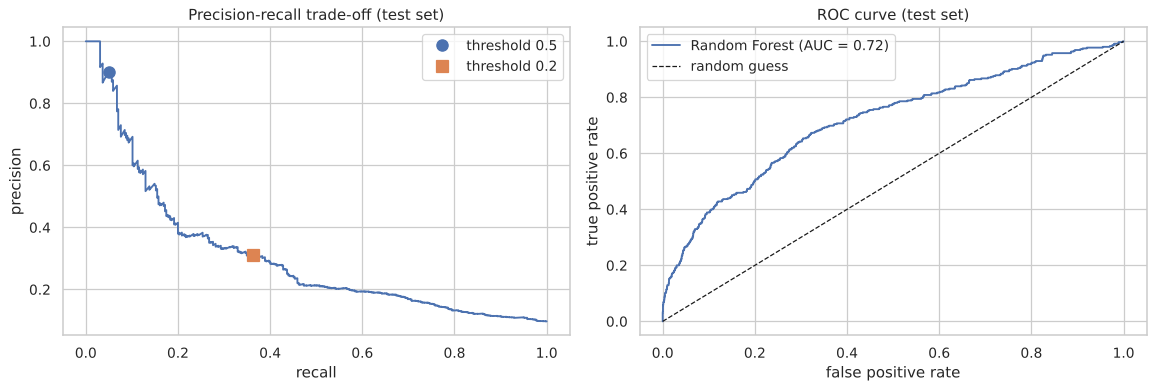

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
prec, rec, thr = metrics.precision_recall_curve(y_test, proba_test)
axes[0].plot(rec, prec, color="#4C72B0")
for t, m in [(0.5, "o"), (best_t, "s")]:
    r = report(y_test, proba_test, t)
    axes[0].plot(r["recall"], r["precision"], m, ms=9, label=f"threshold {t}")
axes[0].set_xlabel("recall"); axes[0].set_ylabel("precision"); axes[0].set_title("Precision-recall trade-off (test set)"); axes[0].legend()

fpr, tpr, _ = metrics.roc_curve(y_test, proba_test)
auc_full = metrics.roc_auc_score(y_test, proba_test)
axes[1].plot(fpr, tpr, label=f"Random Forest (AUC = {auc_full:.2f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="random guess")
axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate"); axes[1].set_title("ROC curve (test set)"); axes[1].legend()
plt.tight_layout()

## 4. Is price the driver? Price-only model vs full model

In [6]:
price_cols = [c for c in X.columns if any(k in c for k in ["dec_jan", "minus", "_std", "max_monthly", "forecast_price"])]
rf_price = RandomForestClassifier(n_estimators=500, min_samples_leaf=2, random_state=SEED, n_jobs=-1)
rf_price.fit(X_train[price_cols], y_train)
auc_price = metrics.roc_auc_score(y_test, rf_price.predict_proba(X_test[price_cols])[:, 1])

print(f"Price-only features ({len(price_cols)}): ROC-AUC = {auc_price:.3f}")
print(f"All features ({X.shape[1]}):        ROC-AUC = {auc_full:.3f}   (0.5 = coin flip)")

Price-only features (11): ROC-AUC = 0.580
All features (39):        ROC-AUC = 0.717   (0.5 = coin flip)


The full model (AUC ≈ 0.72) clearly beats the price-only model (AUC ≈ 0.58). Price features on their own predict churn only a little better than a coin flip — consistent with the EDA.

Share of total importance from price features: 32%


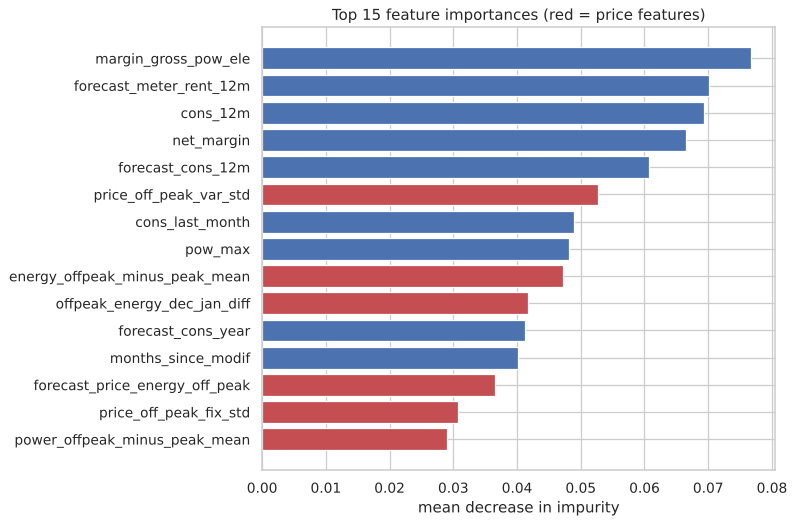

In [7]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
top = imp.tail(15)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.values, color=["#C44E52" if c in price_cols else "#4C72B0" for c in top.index])
ax.set_title("Top 15 feature importances (red = price features)"); ax.set_xlabel("mean decrease in impurity")
plt.tight_layout()
print(f"Share of total importance from price features: {imp[price_cols].sum():.0%}")

The most important features are **margins, consumption and forecast meter rent** — signals about the client's value and usage profile. Some price features (price volatility, off-peak/peak gap) appear in the top 10, so price is not irrelevant, but it is one driver among many rather than *the* driver.
*Caveat: impurity-based importance favours continuous variables; permutation importance or SHAP would be the next check.*

## 5. What the retention team gets: targeting the riskiest 10%

In [8]:
test = df.loc[X_test.index, ["id", "churn", "net_margin"]].copy()
test["churn_probability"] = proba_test
test = test.sort_values("churn_probability", ascending=False)
top10 = test.head(int(len(test) * 0.10))

lift_table = pd.DataFrame({
    "clients": [len(test), len(top10)],
    "churn_rate": [test["churn"].mean(), top10["churn"].mean()],
    "share_of_all_churners": [1.0, top10["churn"].sum() / test["churn"].sum()],
    "share_of_churned_net_margin": [1.0, top10.loc[top10.churn == 1, "net_margin"].sum() / test.loc[test.churn == 1, "net_margin"].sum()],
}, index=["all test clients", "top 10% by risk"])
lift = lift_table.loc["top 10% by risk", "churn_rate"] / lift_table.loc["all test clients", "churn_rate"]
print(f"Top-decile churn rate is {lift:.1f}x the average")
lift_table.round(3)

Top-decile churn rate is 3.3x the average


,clients,churn_rate,share_of_all_churners,share_of_churned_net_margin
all test clients,3652,0.097,1.000,1.00
top 10% by risk,365,0.323,0.332,0.33


**Targeting the riskiest 10% of clients:**
- their actual churn rate is ~32%, **about 3.3x the 9.7% average**
- they contain about **one third of all churners** and about one third of the net margin held by churning clients
- so a retention team working one list of 1 in 10 clients would reach 1 in 3 of the clients who are about to leave

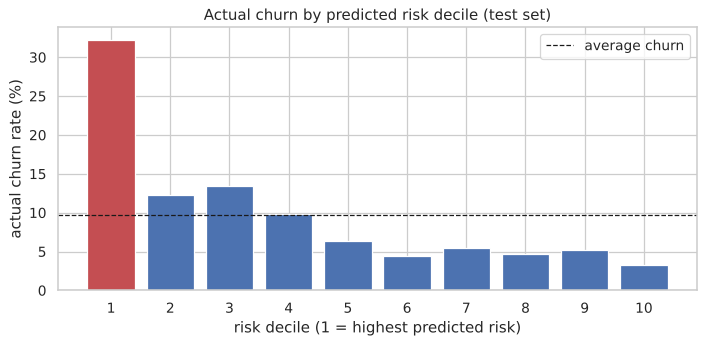

In [9]:
deciles = test.assign(decile=pd.qcut(test["churn_probability"].rank(method="first", ascending=False), 10, labels=range(1, 11)))
by_decile = deciles.groupby("decile", observed=True)["churn"].mean() * 100
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_decile.index.astype(str), by_decile.values, color=["#C44E52"] + ["#4C72B0"] * 9)
ax.axhline(test["churn"].mean() * 100, color="k", ls="--", lw=1, label="average churn")
ax.set_xlabel("risk decile (1 = highest predicted risk)"); ax.set_ylabel("actual churn rate (%)")
ax.set_title("Actual churn by predicted risk decile (test set)"); ax.legend()
plt.tight_layout()

## Conclusions
1. **Price is not the main driver of SME churn.** Prices fell for ~95% of clients in 2015, price-only features predict churn barely better than chance (AUC 0.58), and the full model relies more on margin, consumption and relationship features.
2. **A tuned Random Forest is usable for targeting.** Threshold tuning lifts recall from ~5% to ~36%; the top risk decile churns at ~3.3x the average.
3. **Recommendation:** rather than across-the-board discounts, rank clients by predicted risk and pilot a targeted retention offer on the top decile against a control group, so the incremental effect (and whether any discount pays for itself) can be measured.

In [10]:
test.to_csv("../data/test_predictions.csv", index=False)
print("saved test_predictions.csv")

saved test_predictions.csv
